# CUSTOMER CHURN PREDICTION

1.   The dataset is taken from coursera data science challenge.
2.   The dataset contains real world video streaming platform customer churn data.
3. The task is to build a predictive machine learning model for predicting that a customer will churn or not.
4. The model evaluation is done based on auc-roc score.

## My Evaluation

*   **Training Data Shape:** 243787, 21
*   **Test Data Shape:** 104480, 21
*   **Accuracy-Score:** 0.6822
*   **ROC-AUC-Score:**  0.7486

## Feature Engineering Performed

1. **ChargesPerMonthAccount:**  TotalCharges / AccountAge
2. **DownloadsPerViewingHour:** ContentDownloadsPerMonth / ViewingHoursPerWeek
3. **SupportTicketsPerMonthAge**: SupportTicketsPerMonth / AccountAge
4. **EngagementScore**: (ViewingHoursPerWeek * UserRating) / SupportTicketsPerMonth
5. **ActivityIntensity**: ViewingHoursPerWeek * AverageViewingDuration
6. **CostPerRating**: MonthlyCharges / UserRating
7. **SupportRisk**: SupportTicketsPerMonth * MonthlyCharges / 10
8. **CostPerViewingHour**: MonthlyCharges / ViewingHoursPerWeek
9. **ValueIndex**: ViewingHoursPerWeek * UserRating /    MonthlyCharges
10. **SupportTicketsPerViewingHour**: SupportTicketsPerMonth /ViewingHoursPerWeek
11. **UnproductiveViewing**: AverageViewingDuration * SupportTicketsPerMonth
12. **DownloadsPerSupportTicket**: ContentDownloadsPerMonth /SupportTicketsPerMonth
13. **IsNewUser**: AccountAge <= 12
14. **IsLoyalUser**: AccountAge >= 48

## Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.68      0.78     85409
           1       0.32      0.68      0.44     19071

    accuracy                           0.68    104480
   macro avg       0.62      0.68      0.61    104480
weighted avg       0.80      0.68      0.72    104480



## Top 10 Feature Importance

1. ActivityIntensity (Score: 5155.0)

2. AverageViewingDuration (Score: 5005.0)

3. AccountAge (Score: 4945.0)

4. DownloadsPerSupportTicket (Score: 4683.0)

5. UserRating (Score: 4306.0)

6. MonthlyCharges (Score: 3929.0)

7. UnproductiveViewing (Score: 3725.0)

8. TotalCharges (Score: 3660.0)

9. ViewingHoursPerWeek (Score: 3464.0)

10. ContentDownloadsPerMonth (Score: 3368.0)

In [1]:
import pandas as pd
data_descriptions = pd.read_csv('/content/data_descriptions.csv')
pd.set_option('display.max_colwidth', None)
data_descriptions

,Column_name,Column_type,Data_type,Description
0,AccountAge,Feature,integer,The age of the user's account in months.
1,MonthlyCharges,Feature,float,The amount charged to the user on a monthly basis.
2,TotalCharges,Feature,float,The total charges incurred by the user over the account's lifetime.
3,SubscriptionType,Feature,object,"The type of subscription chosen by the user (Basic, Standard, or Premium)."
4,PaymentMethod,Feature,string,The method of payment used by the user.
5,PaperlessBilling,Feature,string,Indicates whether the user has opted for paperless billing (Yes or No).
6,ContentType,Feature,string,"The type of content preferred by the user (Movies, TV Shows, or Both)."
7,MultiDeviceAccess,Feature,string,Indicates whether the user has access to the service on multiple devices (Yes or No).
8,DeviceRegistered,Feature,string,"The type of device registered by the user (TV, Mobile, Tablet, or Computer)."
9,ViewingHoursPerWeek,Feature,float,The number of hours the user spends watching content per week.


In [2]:
!pip install scikit-plot

# Importing required packages

# Data packages
import pandas as pd
import numpy as np
import shap

# Fix for scikitplot import error due to missing 'interp' in newer SciPy versions
import scipy
if not hasattr(scipy, 'interp'):
    scipy.interp = np.interp

# Machine Learning / Classification packages
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, learning_curve, validation_curve
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV
import scikitplot as skplt

# Visualization Packages
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline

## Load the Data

Let's start by loading the dataset `train.csv` into a dataframe `train_df`, and `test.csv` into a dataframe `test_df` and display the shape of the dataframes.

In [3]:
train_df = pd.read_csv("/content/train.csv")
print('train_df Shape:', train_df.shape)
train_df.head()

train_df Shape: (243787, 21)


,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
0,20,11.055215,221.104302,Premium,Mailed check,No,Both,No,Mobile,36.758104,...,10,Sci-Fi,2.176498,4,Male,3,No,No,CB6SXPNVZA,0
1,57,5.175208,294.986882,Basic,Credit card,Yes,Movies,No,Tablet,32.450568,...,18,Action,3.478632,8,Male,23,No,Yes,S7R2G87O09,0
2,73,12.106657,883.785952,Basic,Mailed check,Yes,Movies,No,Computer,7.395160,...,23,Fantasy,4.238824,6,Male,1,Yes,Yes,EASDC20BDT,0
3,32,7.263743,232.439774,Basic,Electronic check,No,TV Shows,No,Tablet,27.960389,...,30,Drama,4.276013,2,Male,24,Yes,Yes,NPF69NT69N,0
4,57,16.953078,966.325422,Premium,Electronic check,Yes,TV Shows,No,TV,20.083397,...,20,Comedy,3.616170,4,Female,0,No,No,4LGYPK7VOL,0


In [4]:
test = pd.read_csv('/content/test.csv')
test_sol = pd.read_csv('/content/test_sol.csv')

test_df = pd.merge(test, test_sol, on='CustomerID', how='left')
test_df.head()

,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,ContentDownloadsPerMonth,GenrePreference,UserRating,SupportTicketsPerMonth,Gender,WatchlistSize,ParentalControl,SubtitlesEnabled,CustomerID,Churn
0,38,17.869374,679.036195,Premium,Mailed check,No,TV Shows,No,TV,29.126308,...,42,Comedy,3.522724,2,Male,23,No,No,O1W6BHP6RM,0
1,77,9.912854,763.289768,Basic,Electronic check,Yes,TV Shows,No,TV,36.873729,...,43,Action,2.021545,2,Female,22,Yes,No,LFR4X92X8H,0
2,5,15.019011,75.095057,Standard,Bank transfer,No,TV Shows,Yes,Computer,7.601729,...,14,Sci-Fi,4.806126,2,Female,22,No,Yes,QM5GBIYODA,0
3,88,15.357406,1351.451692,Standard,Electronic check,No,Both,Yes,Tablet,35.586430,...,14,Comedy,4.943900,0,Female,23,Yes,Yes,D9RXTK2K9F,0
4,91,12.406033,1128.949004,Standard,Credit card,Yes,TV Shows,Yes,Tablet,23.503651,...,6,Drama,2.846880,6,Female,0,No,No,ENTCCHR1LR,1


**Exploratory Data Analysis**

Doing data analysis to get quick overview of the Data

In [5]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243787 entries, 0 to 243786
Data columns (total 21 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   AccountAge                243787 non-null  int64  
 1   MonthlyCharges            243787 non-null  float64
 2   TotalCharges              243787 non-null  float64
 3   SubscriptionType          243787 non-null  object 
 4   PaymentMethod             243787 non-null  object 
 5   PaperlessBilling          243787 non-null  object 
 6   ContentType               243787 non-null  object 
 7   MultiDeviceAccess         243787 non-null  object 
 8   DeviceRegistered          243787 non-null  object 
 9   ViewingHoursPerWeek       243787 non-null  float64
 10  AverageViewingDuration    243787 non-null  float64
 11  ContentDownloadsPerMonth  243787 non-null  int64  
 12  GenrePreference           243787 non-null  object 
 13  UserRating                243787 non-null  f

Checking for null and duplicates value

In [6]:
print(train_df.duplicated().sum())
train_df.isnull().sum()

0


,0
AccountAge,0
MonthlyCharges,0
TotalCharges,0
SubscriptionType,0
PaymentMethod,0
PaperlessBilling,0
ContentType,0
MultiDeviceAccess,0
DeviceRegistered,0
ViewingHoursPerWeek,0


Plotting heatmap to show the correlation between numerical features. It helps in determining which feature has less or no correlation with the target value and dropping it out.

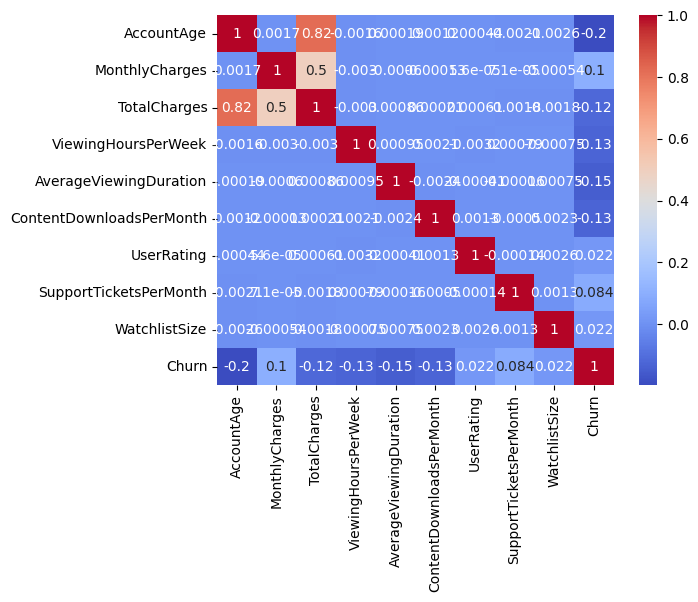

In [7]:
num_corr = train_df.select_dtypes(include='number').corr()
sns.heatmap(num_corr, annot=True, cmap='coolwarm')
plt.show()

Using Pair plot to get the distribution of data on the basis of churn

Using countplot to check whether subscription type affects customer churn. Since no correlation is found we will go with one hot encoding for all the categorical features

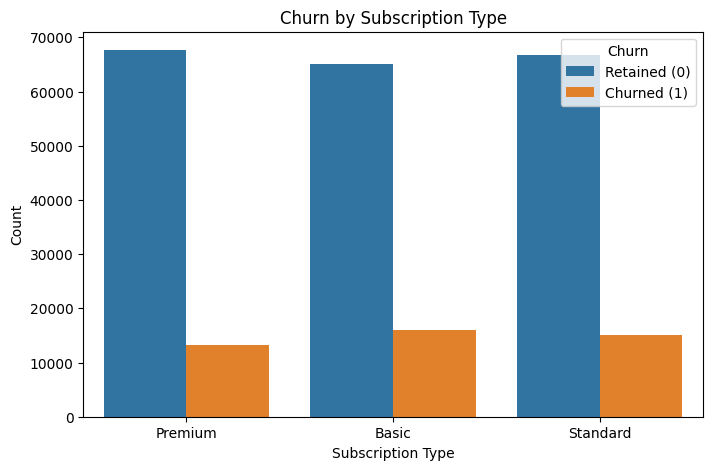

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(x='SubscriptionType', hue='Churn', data=train_df)
plt.title('Churn by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Count')
plt.legend(title='Churn', labels=['Retained (0)', 'Churned (1)'])
plt.show()

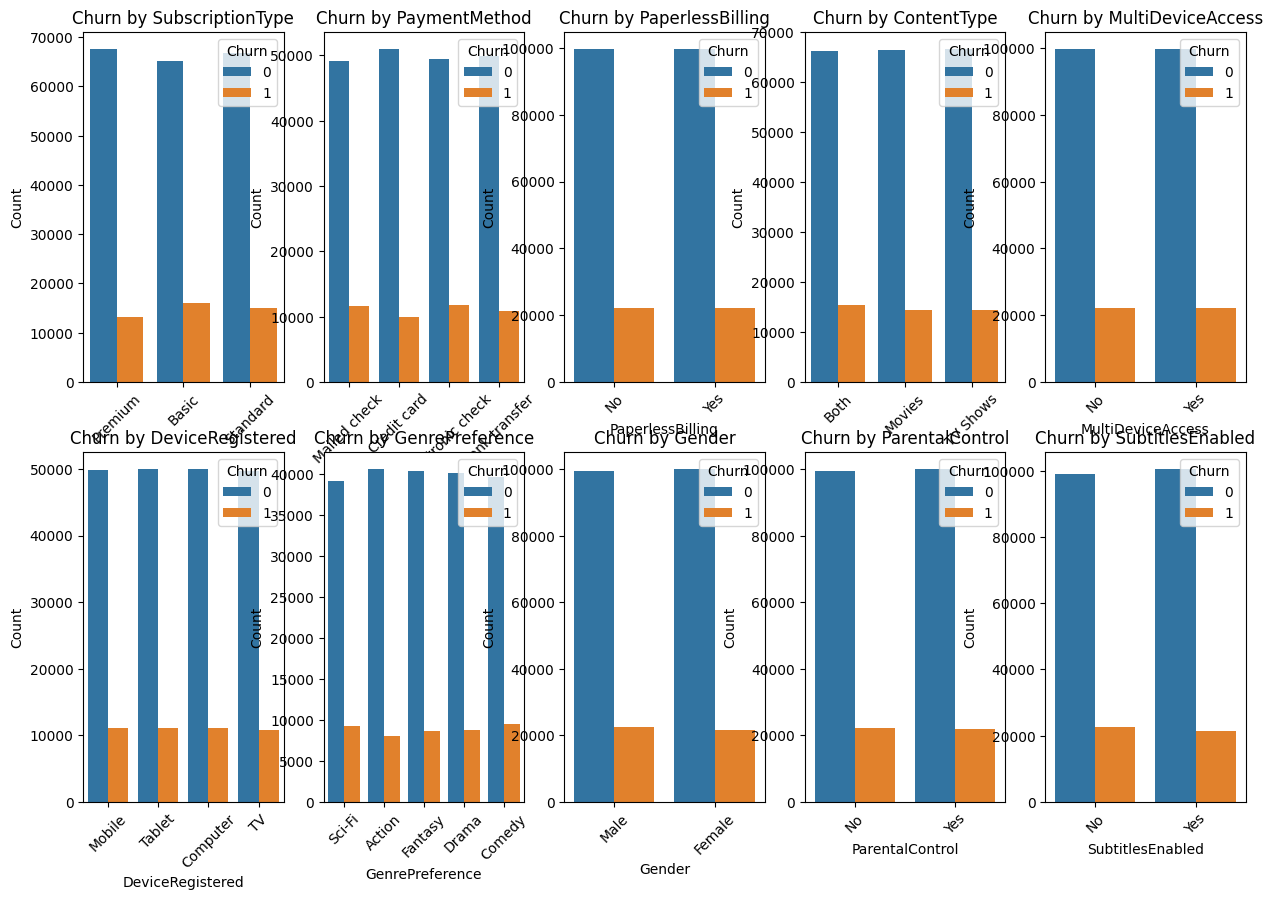

In [9]:
cat_cols = train_df.select_dtypes(include='object').columns
fig, axes =  plt.subplots(nrows=2, ncols=5, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
  if i<len(axes):
    sns.countplot(x=col, hue='Churn', data=train_df, ax=axes[i])
    axes[i].set_title(f'Churn by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)

Checking for potential outliers

In [10]:
num_cols = train_df.select_dtypes(include='number')

for col in num_cols.columns:
  Q1 = num_cols[col].quantile(0.25)
  Q3 = num_cols[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  print(col, ':', (num_cols[col] < lower_bound).sum(), (num_cols[col] > upper_bound).sum())

AccountAge : 0 0
MonthlyCharges : 0 0
TotalCharges : 0 741
ViewingHoursPerWeek : 0 0
AverageViewingDuration : 0 0
ContentDownloadsPerMonth : 0 0
UserRating : 0 0
SupportTicketsPerMonth : 0 0
WatchlistSize : 0 0
Churn : 0 44182


**Feature Engineering**

In [11]:
def engineer_features(df):

    # 1. Charge Efficiency / Averages
    # Average monthly cost relative to account age
    df['ChargesPerMonthAccount'] = df['TotalCharges'] / (df['AccountAge'] + 1)

    # 2. Viewing Intensity
    # How much content they download relative to hours watched
    df['DownloadsPerViewingHour'] = df['ContentDownloadsPerMonth'] / (df['ViewingHoursPerWeek'] + 1)

    # 3. Support Ticket Rate
    # Support tickets relative to account lifetime
    df['SupportTicketsPerMonthAge'] = df['SupportTicketsPerMonth'] / (df['AccountAge'] + 1)

    # 4. Engagement Composite
    df['EngagementScore'] = (df['ViewingHoursPerWeek'] * df['UserRating']) / (df['SupportTicketsPerMonth'] + 1)

    # 1. Total engagement vs cost ratio
    df['ValueRatio'] = df['TotalCharges'] / (df['ViewingHoursPerWeek'] * df['AccountAge'] + 1)

    # 2. Activity intensity index
    df['ActivityIntensity'] = df['ViewingHoursPerWeek'] * df['AverageViewingDuration']

    # 3. Financial stress indicator (High monthly charges relative to user rating)
    df['CostPerRating'] = df['MonthlyCharges'] / (df['UserRating'] + 0.1)

    # 4. Support risk flag
    df['SupportRisk'] = df['SupportTicketsPerMonth'] * (df['MonthlyCharges'] / 10)

    # 5. Basic Numerical Interactions
    df['CostPerViewingHour'] = df['MonthlyCharges'] / (df['ViewingHoursPerWeek'] + 1)
    df['TotalChargesPerMonth'] = df['TotalCharges'] / (df['AccountAge'] + 1)
    df['ValueIndex'] = (df['ViewingHoursPerWeek'] * df['UserRating']) / (df['MonthlyCharges'] + 1)

    # 6. Support & Engagement
    df['SupportTicketsPerViewingHour'] = df['SupportTicketsPerMonth'] / (df['ViewingHoursPerWeek'] + 1)
    df['UnproductiveViewing'] = df['AverageViewingDuration'] * (df['SupportTicketsPerMonth'] + 1)

    # 7. Content downloads activity
    df['DownloadsPerSupportTicket'] = df['ContentDownloadsPerMonth'] / (df['SupportTicketsPerMonth'] + 1)

    # 8. Binning Account Age into segments
    df['IsNewUser'] = (df['AccountAge'] <= 12).astype(int)
    df['IsLoyalUser'] = (df['AccountAge'] >= 48).astype(int)

    return df

# Apply to train and test sets
train_df = engineer_features(train_df)
test_df = engineer_features(test_df)

In [12]:
train_df.head()

,AccountAge,MonthlyCharges,TotalCharges,SubscriptionType,PaymentMethod,PaperlessBilling,ContentType,MultiDeviceAccess,DeviceRegistered,ViewingHoursPerWeek,...,CostPerRating,SupportRisk,CostPerViewingHour,TotalChargesPerMonth,ValueIndex,SupportTicketsPerViewingHour,UnproductiveViewing,DownloadsPerSupportTicket,IsNewUser,IsLoyalUser
0,20,11.055215,221.104302,Premium,Mailed check,No,Both,No,Mobile,36.758104,...,4.856239,4.422086,0.292791,10.528776,6.636457,0.105938,317.656887,2.000000,0,0
1,57,5.175208,294.986882,Basic,Credit card,Yes,Movies,No,Tablet,32.450568,...,1.446141,4.140167,0.154712,5.085981,18.280127,0.239159,231.530352,2.000000,0,1
2,73,12.106657,883.785952,Basic,Mailed check,Yes,Movies,No,Computer,7.395160,...,2.790309,7.263994,1.442100,11.943053,2.391669,0.714698,401.548426,3.285714,0,1
3,32,7.263743,232.439774,Basic,Electronic check,No,TV Shows,No,Tablet,27.960389,...,1.659900,1.452749,0.250816,7.043630,14.467897,0.069060,394.612522,10.000000,0,0
4,57,16.953078,966.325422,Premium,Electronic check,Yes,TV Shows,No,TV,20.083397,...,4.561975,6.781231,0.804096,16.660783,4.045267,0.189723,226.783265,4.000000,0,1


In [13]:
# X_train = train_df.drop(['CustomerID', 'Churn'], axis=1)
# X_test = test_df.drop(['CustomerID', 'Churn'], axis=1)
# y_train = train_df.Churn
# y_test = test_df.Churn


# # Compute ratio for class imbalance
# ratio = (y_train == 0).sum() / (y_train == 1).sum()

# num_cols = X_train.select_dtypes(include='number').columns
# cat_cols = X_train.select_dtypes(include='object').columns

# preprocessor = ColumnTransformer(
#     transformers=[
#         ('num', 'passthrough', num_cols),
#         ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
#     ]
# )

# clf_pipeline = Pipeline(steps=[
#     ('preprocessor', preprocessor),
#     ('model', XGBClassifier(objective='binary:logistic', eval_metric='logloss', scale_pos_weight=ratio, random_state=42))
# ])

# param_distributions = {
#     'model__n_estimators': [100, 200, 300, 500],
#     'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
#     'model__max_depth': [3, 4, 5, 6, 7],
#     'model__min_child_weight': [1, 3, 5, 7],
#     'model__subsample': [0.6, 0.7, 0.8, 0.9],
#     'model__colsample_bytree': [0.6, 0.7, 0.8, 0.9],
#     'model__gamma': [0, 0.1, 0.2, 0.5, 1.0],
#     'model__reg_alpha': [0, 0.1, 1.0, 5.0],
#     'model__reg_lambda': [1.0, 2.0, 5.0, 10.0]
# }

# random_search = RandomizedSearchCV(clf_pipeline, param_distributions, cv=5, n_iter=15, scoring='roc_auc', random_state=42, n_jobs=-1)
# random_search.fit(X_train, y_train)

Training the model on the best params generated using **RandomizedRearchCV**

In [14]:
train_clean = train_df.dropna(subset=['Churn'])

X_train = train_clean.drop(['CustomerID', 'Churn'], axis=1)
X_test = test_df.drop(['CustomerID', 'Churn'], axis=1)
y_train = train_clean.Churn
y_test = test_df.Churn


# Compute ratio for class imbalance
ratio = (y_train == 0).sum() / (y_train == 1).sum()

num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(include='object').columns

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

params = {
    'subsample': 0.8,
    'reg_lambda': 5.0,
    'reg_alpha': 0,
    'n_estimators': 1500,
    'min_child_weight': 3,
    'max_depth': 6,
    'learning_rate': 0.01,
    'gamma': 1.0,
    'colsample_bytree': 0.6
}

clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        scale_pos_weight=ratio,
        random_state=42,
        **params
        ))
])



In [15]:
clf_pipeline.fit(X_train, y_train)

clf_preds_train = clf_pipeline.predict(X_train)
clf_preds_test = clf_pipeline.predict(X_test)

clf_pred_proba_train = clf_pipeline.predict_proba(X_train)[:, 1]
clf_pred_proba_test = clf_pipeline.predict_proba(X_test)[:, 1]

In [16]:
clf_auc_score_train = roc_auc_score(y_train, clf_pred_proba_train)
clf_auc_score_test = roc_auc_score(y_test, clf_pred_proba_test)

clf_accuracy_score_train = accuracy_score(y_train, clf_preds_train)
clf_accuracy_score_test = accuracy_score(y_test, clf_preds_test)

print(f"Train AUC-ROC Score: {clf_auc_score_train:.4f}")
print(f"Test AUC-ROC Score: {clf_auc_score_test:.4f}")
print(f"Train Accuracy Score: {clf_accuracy_score_train:.4f}")
print(f"Test Accuracy Score: {clf_accuracy_score_test:.4f}")

Train AUC-ROC Score: 0.7868
Test AUC-ROC Score: 0.7486
Train Accuracy Score: 0.6988
Test Accuracy Score: 0.6822


***Plotting the top 10 Features Importance***



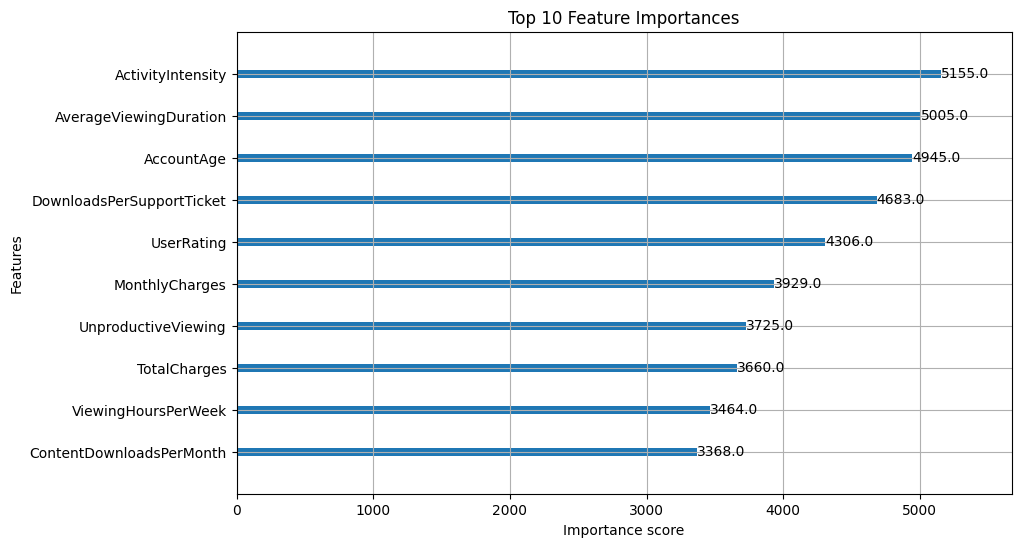

In [17]:
# 1. Getting model and processor from pipeline
preprocessor = clf_pipeline.named_steps['preprocessor']
model = clf_pipeline.named_steps['model']

# 2. Getting categorical and numerical feature names
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols).tolist()
all_feature_names = list(num_cols) + encoded_cat_cols


model.get_booster().feature_names = all_feature_names

# 3. Plotting the Graph
plt.figure(figsize=(10, 6))
xgb.plot_importance(model, max_num_features=10, ax=plt.gca())
plt.title('Top 10 Feature Importances')
plt.show()

**Plotting the last tree generated by the model**

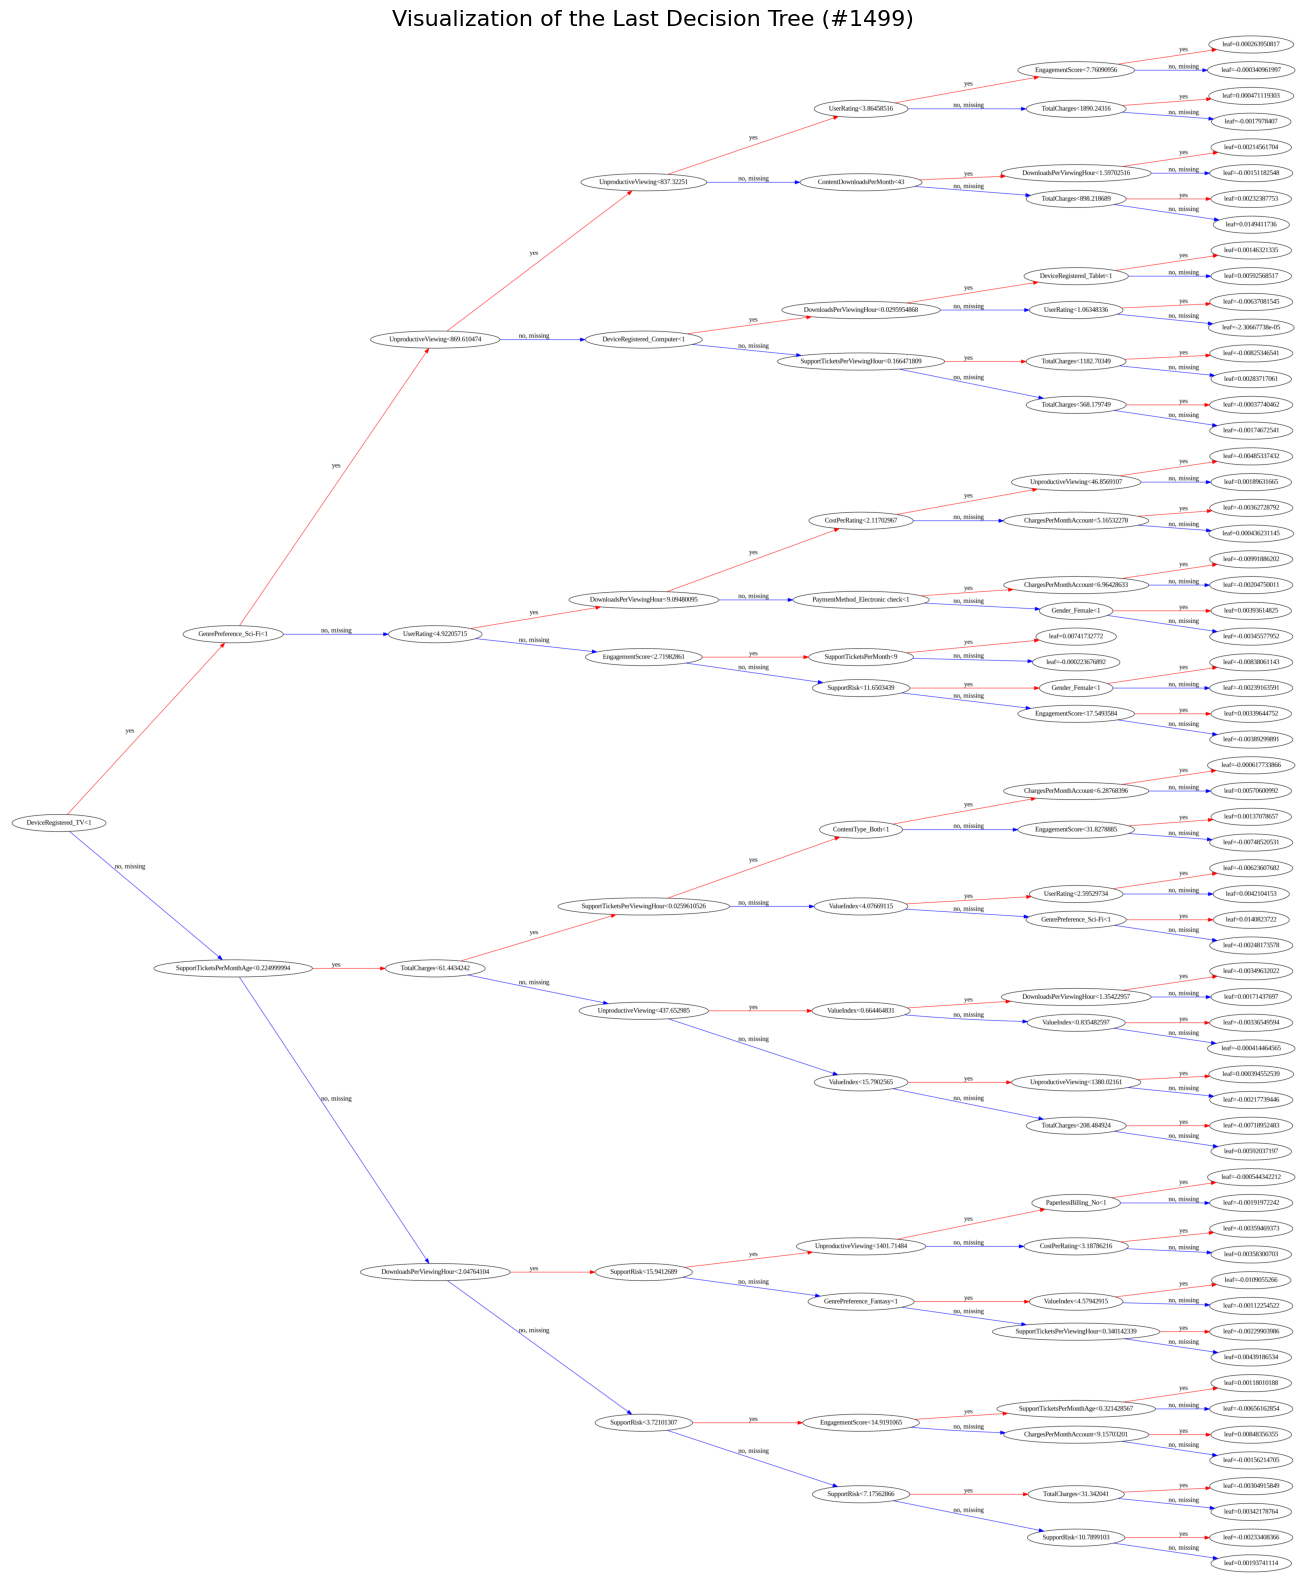

In [18]:
# Getting the index of the last tree
last_tree_idx = model.n_estimators - 1

# Seting up the plot figure size
plt.figure(figsize=(20, 20))

# Plotting the last tree using 'tree_idx'
xgb.plot_tree(model, tree_idx=last_tree_idx, ax=plt.gca(), rankdir='LR')

plt.title(f'Visualization of the Last Decision Tree (#{last_tree_idx})', fontsize=16)
plt.show()

In [19]:
# Printing classification report to get the precision, recall and f1-score for better model evaluation
class_report = classification_report(y_test, clf_preds_test)
print("Classification Report:\n", class_report)

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.68      0.78     85409
           1       0.32      0.68      0.44     19071

    accuracy                           0.68    104480
   macro avg       0.62      0.68      0.61    104480
weighted avg       0.80      0.68      0.72    104480



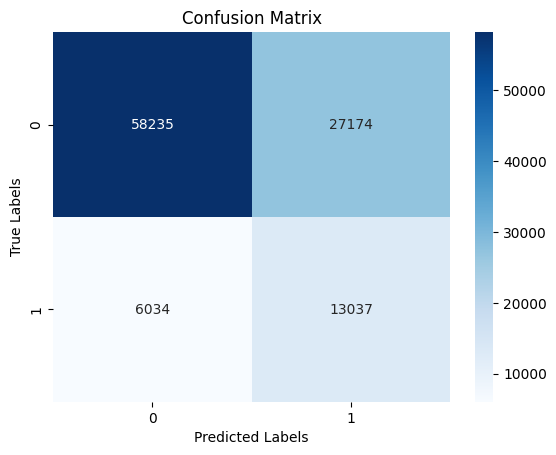

In [20]:
cm = confusion_matrix(y_test, clf_preds_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

Test ROC-AUC Score: 0.7486


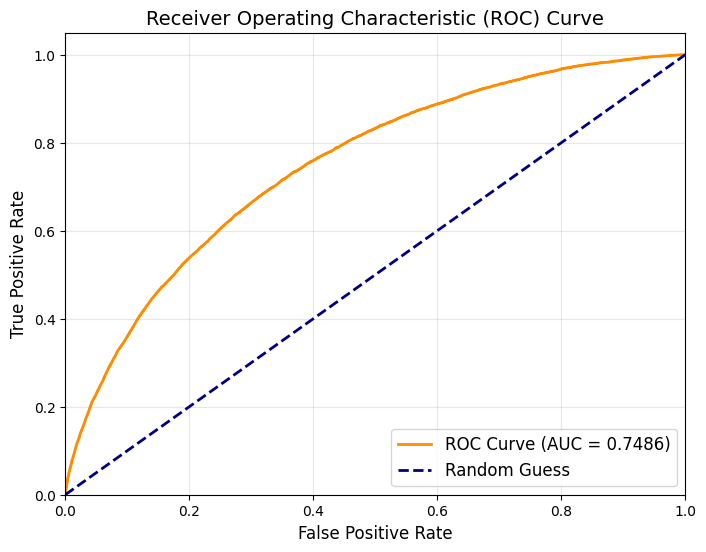

In [21]:
# 1. Get predicted probabilities for the test set (probability of class 1)
y_pred_proba = clf_pipeline.predict_proba(X_test)[:, 1]

# 2. Calculate the ROC-AUC score
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"Test ROC-AUC Score: {auc_score:.4f}")

# 3. Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# 4. Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.grid(alpha=0.3)
plt.show()

**Plotting Precision Recall Curve to get better visualization of precision-recall trade-off**

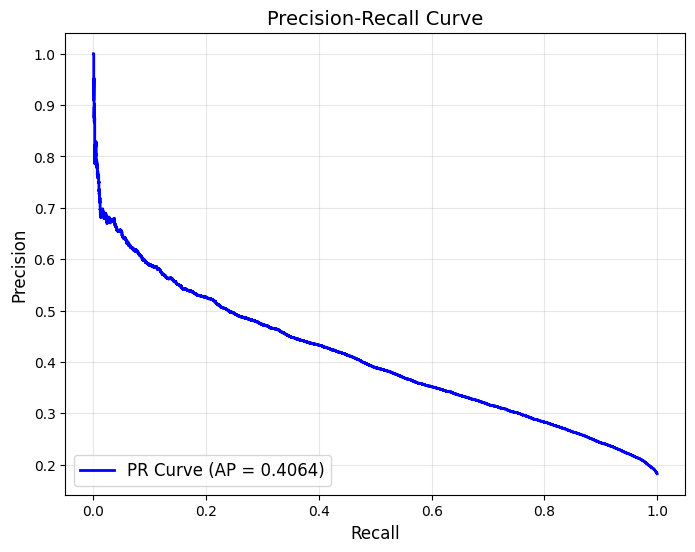

In [22]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculating precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, clf_pred_proba_test)
ap_score = average_precision_score(y_test, clf_pred_proba_test)

# Plot PR Curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue', lw=2, label=f'PR Curve (AP = {ap_score:.4f})')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve', fontsize=14)
plt.legend(loc="lower left", fontsize=12)
plt.grid(alpha=0.3)
plt.show()

In [23]:
# # Define a range of depths to test model complexity
# depths = [2, 3, 4, 5, 6, 8, 10]

# # Compute validation curves for training and test sets
# train_scores, test_scores = validation_curve(
#     clf_pipeline, X_train, y_train,
#     param_name="model__max_depth",
#     param_range=depths,
#     scoring="roc_auc",
#     cv=3,
#     n_jobs=-1
# )

# # Calculate mean scores across cross-validation folds
# train_mean = np.mean(train_scores, axis=1)
# test_mean = np.mean(test_scores, axis=1)

# # Plotting the trade-off curve
# plt.figure(figsize=(9, 6))
# plt.plot(depths, train_mean, label="Training Score (AUC)", color="blue", marker="o", lw=2)
# plt.plot(depths, test_mean, label="Validation Score (AUC)", color="orange", marker="o", lw=2)

# plt.xlabel("Model Complexity (Max Depth)", fontsize=12)
# plt.ylabel("ROC-AUC Score", fontsize=12)
# plt.title("Bias-Variance Tradeoff: Complexity vs Performance", fontsize=14)
# plt.legend(loc="best", fontsize=11)
# plt.grid(alpha=0.3)
# plt.show()

In [24]:
# # Compute learning curves across varying training set sizes
# train_sizes, train_scores, test_scores = learning_curve(
#     clf_pipeline, X_train, y_train,
#     cv=2,
#     scoring="roc_auc",
#     train_sizes=np.linspace(0.1, 1.0, 5),
#     n_jobs=-1
# )

# train_mean = np.mean(train_scores, axis=1)
# test_mean = np.mean(test_scores, axis=1)

# plt.figure(figsize=(9, 6))
# plt.plot(train_sizes, train_mean, label="Training Score", color="blue", marker="o")
# plt.plot(train_sizes, test_mean, label="Cross-Validation Score", color="orange", marker="o")

# plt.xlabel("Training Set Size", fontsize=12)
# plt.ylabel("ROC-AUC Score", fontsize=12)
# plt.title("Learning Curve (Bias & Variance Diagnostics)", fontsize=14)
# plt.legend(loc="best", fontsize=11)
# plt.grid(alpha=0.3)
# plt.show()

**Plotting shap graph to visualize how feature affects the prediction**

In [25]:
# # 1. Transform your X_test data using the pipeline's preprocessor
# X_test_transformed = preprocessor.transform(X_test)

# # 2. Extract feature names after encoding
# cat_encoder = preprocessor.named_transformers_['cat']
# encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols).tolist()
# all_feature_names = list(num_cols) + encoded_cat_cols

# # 3. Create a TreeExplainer using the XGBoost model
# explainer = shap.TreeExplainer(model)
# shap_values = explainer(X_test_transformed)

# # 4. Plot the summary (beeswarm plot)
# plt.figure(figsize=(12, 8))
# shap.summary_plot(shap_values, X_test_transformed, feature_names=all_feature_names, max_display=10)

**Plotting cumulative gains chart**

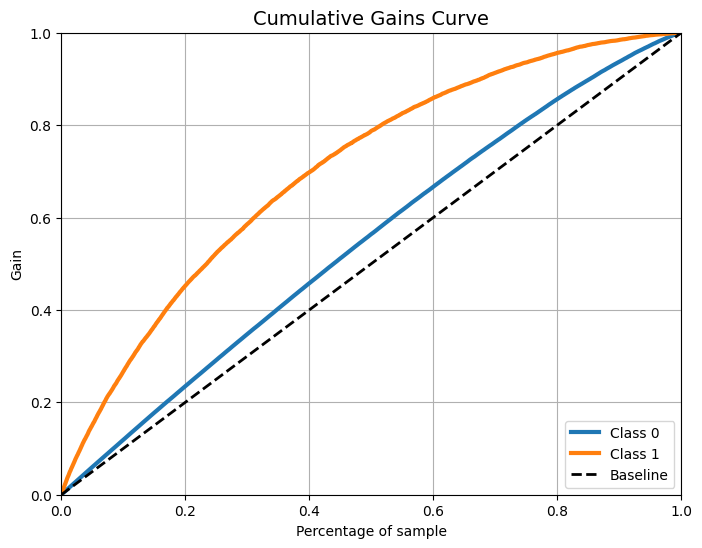

In [26]:
plt.figure(figsize=(8, 6))
skplt.metrics.plot_cumulative_gain(y_test, clf_pipeline.predict_proba(X_test), ax=plt.gca())
plt.title('Cumulative Gains Curve', fontsize=14)
plt.show()

In [27]:
import joblib

model = clf_pipeline
joblib.dump(model, 'model.joblib')

['model.joblib']